# Dar_026 — ShadowCam manual south-polar environmental support

## Questions
- Do label bytes, dtype, CRS and pixel scale agree?
- Which study-region centres are geometrically inside and which have ordinary image pixels?
- How many fixed-patch pixels are NULL/saturated/nonfinite?
- How does signed radiance vary within supported region/terrain/visibility contexts?
- How do parent-shadow cohorts differ?
- Which coverage/geometry holds prevent site-scoring claims?

In [3]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT/'darrel stuff/EDA'), str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import rasterio
from rasterio.enums import Resampling
from environment_workflow import LocalRun as Run, latest_completed_run
from decision_eda import accepted_input
import manual_raster_eda as methods
REGION_LIMIT=None
MANUAL_INVENTORY=DATA/'manifests/eda_datasets/20261107T182412585915Z/inventory.json'
CONTEXT_RUN='20261106T134155791814Z_c6f9ab'

def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=120,bbox_inches='tight')
    display(fig); plt.close(fig)

def finite_hist(ax, values, label):
    finite=np.asarray(values); finite=finite[np.isfinite(finite)]
    if len(finite):
        ax.hist(finite,bins=70)
    else:
        ax.text(.5,.5,'No supported values in this declared sample',ha='center',transform=ax.transAxes)
    ax.set(xlabel=label,ylabel='Declared sample count')

def context_input(run):
    folder=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',CONTEXT_RUN)
    path=accepted_input(run,folder,'native_center_context.csv.gz')
    frame=pd.read_csv(path)
    if frame.duplicated(['region','clon','clat']).any():raise ValueError('Duplicate context centres')
    if REGION_LIMIT is not None:
        preferred='A3CLR22_3_Faustini_Rim_A'
        regions=[preferred]+[r for r in sorted(frame.region.unique()) if r!=preferred]
        frame=frame.loc[frame.region.isin(regions[:REGION_LIMIT])].copy()
    return frame

def save_context_results(run, frame):
    summary=methods.regional_summary(frame)
    unique,relationships,contrasts=methods.relationship_tables(frame)
    frame.to_csv(run.path('source_at_environment_centres.csv.gz'),index=False,compression='gzip')
    summary.to_csv(run.path('regional_source_support.csv'),index=False)
    unique.to_csv(run.path('distinct_source_pixel_context.csv.gz'),index=False,compression='gzip')
    relationships.to_csv(run.path('within_region_relationships.csv'),index=False)
    contrasts.to_csv(run.path('parent_shadow_context_distributions.csv'),index=False)
    frame.groupby(['region','pixel_status']).size().rename('centres').reset_index().to_csv(run.path('centre_pixel_status_counts.csv'),index=False)
    display(summary); display(relationships)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    labels=[r.split('_',2)[-1].replace('_',' ') for r in summary.region]
    axes[0].barh(labels,summary.support_fraction_of_context_centres)
    axes[0].set(xlabel='Supported fraction of existing thermal/context centres',xlim=(0,1),title='Point support, not area/footprint certification')
    for region,part in unique.groupby('region'):
        axes[1].scatter(part.slope_deg,part.analysis_value,s=3,alpha=.25,label=region.split('_',2)[-1])
    axes[1].set(xlabel='Existing LOLA slope (degrees)',ylabel='Source value (declared cohort)',title='Native-source-pixel context; not causal')
    if len(unique):axes[1].legend(fontsize=6)
    savefig(run,fig,'regional_support_and_slope_context')
    fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
    supported=relationships.loc[relationships.status.eq('descriptive')]
    if len(supported):
        for region,part in supported.groupby('region'):
            ax.scatter(part.predictor,part.spearman_rho,label=region.split('_',2)[-1],s=25)
        ax.legend(fontsize=6)
    else:ax.text(.5,.5,'No supported within-region comparisons',ha='center',transform=ax.transAxes)
    ax.axhline(0,color='grey',lw=.5);ax.set(ylabel='Descriptive Spearman rho',ylim=(-1.05,1.05))
    savefig(run,fig,'within_region_context_associations')
    return summary,relationships,contrasts

## Sources and interpretation
Original source bytes stay in `darrel stuff/data/`, with explicit manual-import inventory/receipts. Their SHA-256 values are local integrity baselines, **not publisher checksums**. The `.xml.txt` label is parsed in place, not renamed or substituted.

- [ShadowCam archive SIS](https://pds.shadowcam.im-ldi.com/document/archsis.pdf): calibrated map products and uncontrolled geometric limitations.
- [Mini-RF global mosaic user guide](https://pds-geosciences.wustl.edu/lro/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/document/userguide.txt): mixed viewing geometry, uncontrolled/unorthorectified products and strip-gradient caveats.
- [USGS ISIS float32 special-pixel definitions](https://isis.astrogeology.usgs.gov/7.2.0/Object/Developer/_special_pixel_8h_source.html): NULL, low/high instrument and representation saturation are not measurements.

Relationships are within-region descriptions at distinct source pixels (context predictors use medians when several existing centres address one source pixel). Parent shadow classes are retained only when all contributing centres agree; mixed/unknown assignments stay separate. Twenty pairs is a descriptive/numerical safeguard, not independent-trial evidence or an operational requirement. No missing value is filled with zero.


Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


,region,context_centres,inside_source_grid,ordinary_pixels,negative_ordinary_pixels,analysis_centres,distinct_analysis_source_pixels,support_fraction_of_context_centres,count,minimum,q10,median,q90,maximum
0,A3CLR22_10_Leibnitz_Beta_Plateau,4422,0,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN
1,A3CLR22_11_Malapert_Massif,7569,0,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN
2,A3CLR22_12_deGerlache_Kocher_Massif,6972,0,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN
3,A3CLR22_2_Haworth,15500,2692,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN
4,A3CLR22_3_Faustini_Rim_A,6972,6631,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN
5,A3CLR22_4_deGerlache_Rim_2,6889,6889,1455,0,1455,1455,0.211206,1455,0.001712,0.003977,0.008709,0.081117,0.687555
6,A3CLR22_5_Connecting_Ridge_Extension,7056,2615,0,0,0,0,0.000000,0,NaN,NaN,NaN,NaN,NaN


,region,predictor,distinct_source_pixels,status,spearman_rho
0,A3CLR22_10_Leibnitz_Beta_Plateau,solar_visibility,0,insufficient_rows,NaN
1,A3CLR22_10_Leibnitz_Beta_Plateau,earth_visibility,0,insufficient_rows,NaN
2,A3CLR22_10_Leibnitz_Beta_Plateau,sky_view_sr,0,insufficient_rows,NaN
3,A3CLR22_10_Leibnitz_Beta_Plateau,elevation_m,0,insufficient_rows,NaN
4,A3CLR22_10_Leibnitz_Beta_Plateau,slope_deg,0,insufficient_rows,NaN
5,A3CLR22_11_Malapert_Massif,solar_visibility,0,insufficient_rows,NaN
6,A3CLR22_11_Malapert_Massif,earth_visibility,0,insufficient_rows,NaN
7,A3CLR22_11_Malapert_Massif,sky_view_sr,0,insufficient_rows,NaN
8,A3CLR22_11_Malapert_Massif,elevation_m,0,insufficient_rows,NaN
9,A3CLR22_11_Malapert_Massif,slope_deg,0,insufficient_rows,NaN


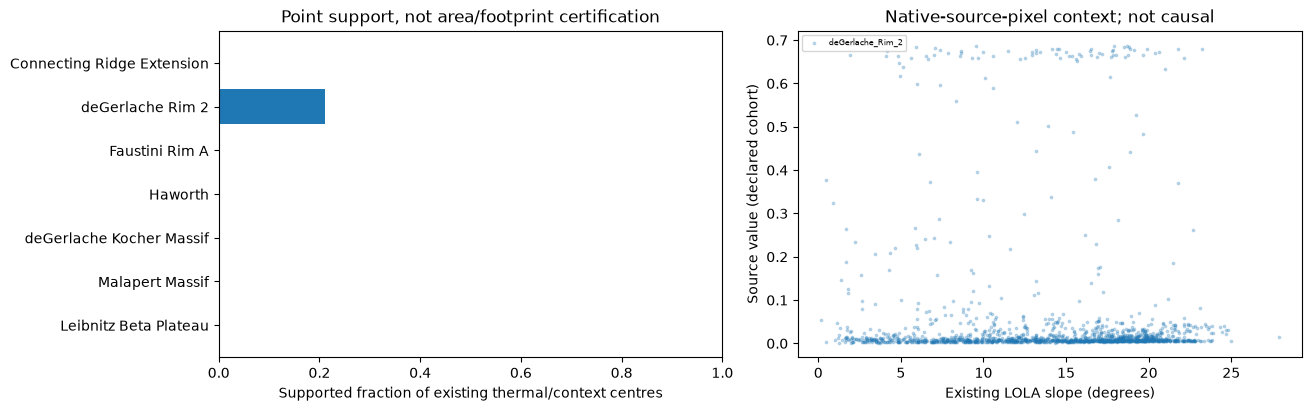

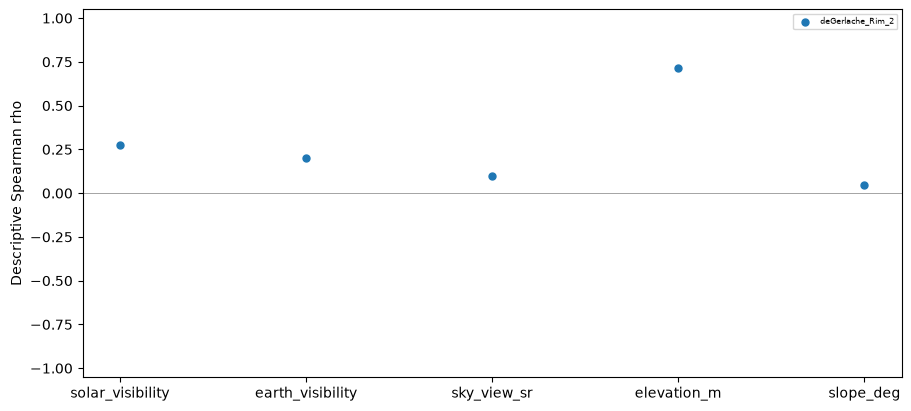

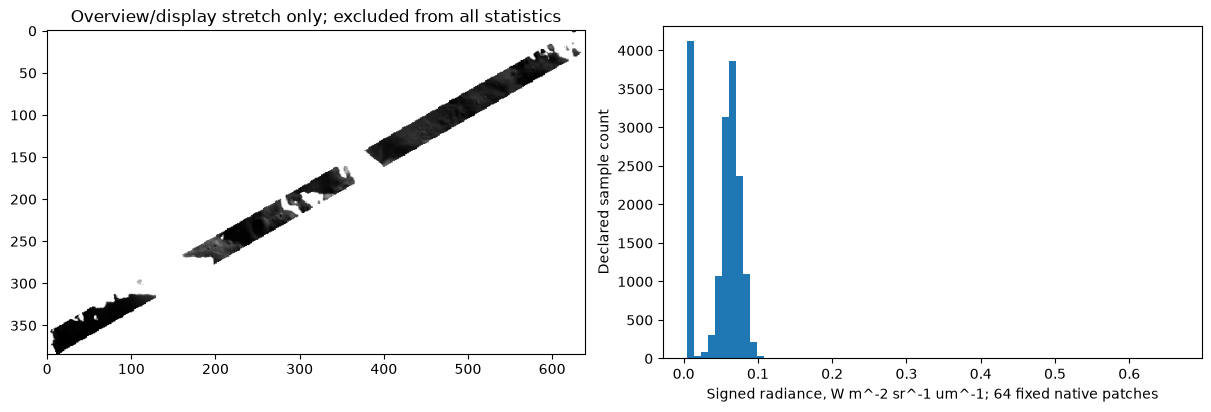

{'source_metadata': {'shape': [43008, 74942],
  'dtype': 'float32',
  'crs': 'PROJCS["polarstereographic MOON",GEOGCS["GCS_MOON",DATUM["D_MOON",SPHEROID["MOON_polarRadius",1737400,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",-88.12],PARAMETER["central_meridian",20.56],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",NORTH],AXIS["Northing",NORTH]]',
  'transform': [1.84723, 0.0, -69215.7081, 0.0, -1.84723, 66077.26433],
  'resolution_m': [1.84723, 1.84723],
  'nodata': -3.4028226550889045e+38,
  'unit': 'W m^-2 sr^-1 um^-1',
  'unit_basis': 'ShadowCam archive SIS calibrated map definition; TIFF band unit absent',
  'projection_note': 'Native TIFF variant B used unchanged: XML origin-latitude value corresponds to its standard parallel, not its pole',
  'label_suffix': '.txt',
  'special_pixel_policy': 'https://isis.astrogeology.usgs.g

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_026_shadowcam_manual\20261109T151404320594Z_faf7bb


In [4]:
with Run(ROOT,'analysis/dar_026_shadowcam_manual',{'dataset':'D27','source_product':'M013049982S',
    'region_limit':REGION_LIMIT,'patch_grid':8,'patch_side':64,'minimum_relationship_pairs':20,
    'control':'ordinary signed native radiance; no physical registration or calibrated feature/ice inference'},
    'Moon/Dar_026_shadowcam_manual_environment.ipynb') as run:
    run.input(Path(methods.__file__))
    paths=methods.manual_selection(DATA,MANUAL_INVENTORY,'D27',run)
    meta=methods.shadow_definition(paths['label'],paths['image'])
    frame=context_input(run)
    values,rows,cols,inside,nodata=methods.sample_shadow(paths['image'],frame.clon.to_numpy(),frame.clat.to_numpy())
    paired=methods.attach_pixels(frame,values,rows,cols,inside,nodata=nodata)
    sample,patches=methods.shadow_patch_sample(paths['image'],grid=8,side=64)
    statuses=methods.classify_pixels(sample,nodata)
    patches.to_csv(run.path('native_patch_sample.csv'),index=False)
    pd.Series(statuses).value_counts().rename_axis('pixel_status').rename('pixels').to_csv(run.path('sample_pixel_status_counts.csv'))
    summary,relationships,contrasts=save_context_results(run,paired)
    with rasterio.Env(GDAL_CACHEMAX=16*1024**2), rasterio.open(paths['image']) as src:
        overview=src.read(1,out_shape=(384,640),resampling=Resampling.nearest)
    overview=np.where(methods.classify_pixels(overview,nodata)=='valid',overview,np.nan)
    fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    finite=overview[np.isfinite(overview)]
    if len(finite):
        low,high=np.quantile(finite,[.02,.98]);axes[0].imshow(overview,cmap='gray',vmin=low,vmax=high)
    else:axes[0].text(.5,.5,'No ordinary pixels in display overview',ha='center')
    axes[0].set(title='Overview/display stretch only; excluded from all statistics')
    finite_hist(axes[1],sample[statuses=='valid'],'Signed radiance, W m^-2 sr^-1 um^-1; 64 fixed native patches')
    savefig(run,fig,'shadowcam_display_and_native_sample')
    findings={'source_metadata':meta,'context_centres':len(paired),'inside_image_rectangle':int(inside.sum()),
        'ordinary_image_centres':int(paired.ordinary_pixel.sum()),'negative_ordinary_centres':int((paired.ordinary_pixel & paired.raw_value.lt(0)).sum()),
        'regions_with_grid_overlap':int(summary.inside_source_grid.gt(0).sum()),
        'regions_with_ordinary_pixel_support':int(summary.analysis_centres.gt(0).sum()),
        'sampled_native_patches':len(patches),'sampled_native_pixels':len(sample),
        'sample_pixel_statuses':pd.Series(statuses).value_counts().to_dict(),
        'relationship_statuses':relationships.status.value_counts().to_dict(),
        'holds':['Existing thermal/context centres are selected, not a full image/region census',
                 'Image radiance depends on lighting/calibration, not albedo, temperature, ice or hazard directly',
                 'CRS-based centre lookups are not physically validated co-registration or full-footprint coverage',
                 'Static means, dated image and cumulative thermal context are not simultaneous conditions',
                 'Native fixed-patch statistics are not whole-image or area-weighted statistics']}
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(findings)
OUT=run.directory;print('Completed:',OUT)